# Decision Analysis, Risk Profiles & Project Networks
> *References: Clemen & Reilly, Making Hard Decisions: An Introduction to Decision Analysis; Project Management Institute (PMI) Practice Standard for Project Risk Management.*

Quantitative decision-making requires systematically modeling risks and stochastic rewards.
This notebook demonstrates how the `probability` library unifies:
1. **Expected Value of Perfect Information (EVPI)** in decision problems (e.g. Clemen's classic Oil Drilling problem).
2. **Decision Trees with Continuous Uncertainty**: Incorporating stochastic costs and payoffs (`Normal`, `PERT`) directly into multi-stage decision trees.
3. **Cumulative Risk Profiles**: Constructing exact probability distributions (lotteries) over terminal outcomes to evaluate risk and stochastic dominance.
4. **Stochastic Project Networks (`ProjectNetwork`)**: Modeling complex precedence DAGs with uncertain task durations (`PERT`).
5. **Monte Carlo Project Simulation**: Computing dynamic critical path probabilities, task criticality indices, and the project completion time distribution wrapped as a first-class `Ratio` distribution.

In [1]:
import set_paths
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from probability.distributions.continuous.normal import Normal
from probability.distributions.continuous.pert import PERT
from probability.models.decision_tree import DecisionTree
from probability.models.project_network import ProjectNetwork, ProjectTask
from probability.plotting import new_axes

## 1. Oil Drilling & Expected Value of Perfect Information (EVPI)
Consider the classic oil drilling decision problem from Clemen's *Making Hard Decisions*:
A wildcatter must decide whether to **Drill** or **Don't Drill**.
The geological state of the site is uncertain:
- **Dry** ($50\%$ probability): Drilling loses $-\$100\text{k}$.
- **Wet** ($30\%$ probability): Drilling profits $+\$150\text{k}$.
- **Soaking** ($20\%$ probability): Drilling profits $+\$500\text{k}$.

If the wildcatter does not drill, the payoff is $\$0$ in all states.
**Expected Value of Perfect Information (EVPI)** answers: *What is the maximum amount the wildcatter should pay for a perfectly accurate seismic survey before deciding?*

In [2]:
payoffs = {
    'Drill': {'Dry': -100.0, 'Wet': 150.0, 'Soaking': 500.0},
    'DontDrill': {'Dry': 0.0, 'Wet': 0.0, 'Soaking': 0.0}
}
state_probs = {'Dry': 0.50, 'Wet': 0.30, 'Soaking': 0.20}

df_payoffs = pd.DataFrame(payoffs).T
print('Payoff Matrix ($k):')
display(df_payoffs)

evpi = DecisionTree.calculate_evpi(payoffs, state_probs, minimize=False)
print(f'\nCalculated EVPI: ${evpi:,.2f}k (${evpi * 1000:,.0f})')
print('Interpretation: The decision-maker should pay at most $50,000 for perfect foresight.')

Payoff Matrix ($k):


,Dry,Wet,Soaking
Drill,-100.0,150.0,500.0
DontDrill,0.0,0.0,0.0



Calculated EVPI: $50.00k ($50,000)
Interpretation: The decision-maker should pay at most $50,000 for perfect foresight.


## 2. Multi-Stage Decision Trees with Continuous Uncertainty
In many engineering and business decisions, costs are not fixed numbers—they are stochastic random variables.
Here, an enterprise evaluates two product development strategies:
- **Strategy A: In-House R&D**: Initial research cost is stochastic, modeled as a continuous `Normal(mu=50, sigma=5)`.
  - Succeeds with probability $70\%$.
  - If it fails, the firm faces a secondary **Pivot Decision**:
    - *Acquire a Startup*: Cost $\$60\text{k}$, $85\%$ success.
    - *Abandon Project*: Cost $\$0$.
- **Strategy B: License Partner**: Fixed cost of $\$35\text{k}$ with $80\%$ success.

We solve by backward induction for cost minimization (`minimize=True`).

In [3]:
dt = DecisionTree()
dt.add_decision(name='R&D_Strategy')

# Choice A: In-House R&D with continuous Normal cost distribution
dt.add_option(name='InHouse_RD', p_success=0.70, amount=Normal(50, 5), parent_name='R&D_Strategy')

# Pivot decision upon in-house failure
dt.add_decision(name='Pivot_Decision', parent_name='InHouse_RD')
dt.add_option(name='Acquire_Startup', p_success=0.85, amount=60.0, parent_name='Pivot_Decision', final=True)
dt.add_option(name='Abandon_Project', p_success=1.00, amount=0.0, parent_name='Pivot_Decision', final=True)

# Choice B: Licensing
dt.add_option(name='License_Partner', p_success=0.80, amount=35.0, parent_name='R&D_Strategy', final=True)

# Solve by backward induction for cost minimization
dt.solve(minimize=True)

print('--- Solved Expected Costs ---')
print(f"In-House R&D Expected Cost:     ${dt.chance_node('InHouse_RD').expected_amount:.2f}k")
print(f"License Partner Expected Cost:   ${dt.chance_node('License_Partner').expected_amount:.2f}k")

--- Solved Expected Costs ---
In-House R&D Expected Cost:     $50.00k
License Partner Expected Cost:   $35.00k


## 3. Cumulative Risk Profiles
Expected value alone does not tell the full story—a decision maker cares about downside risk.
A **Risk Profile** summarizes the complete probability distribution (lottery) over all terminal outcomes under the optimal policy.
We inspect the table and plot the cumulative risk profile step CDF.

,outcome,probability,amount,cumulative_probability
0,InHouse_RD.success,0.7,50.0,0.7
1,Abandon_Project.success,0.3,50.0,1.0
2,Abandon_Project.failure,0.0,50.0,1.0


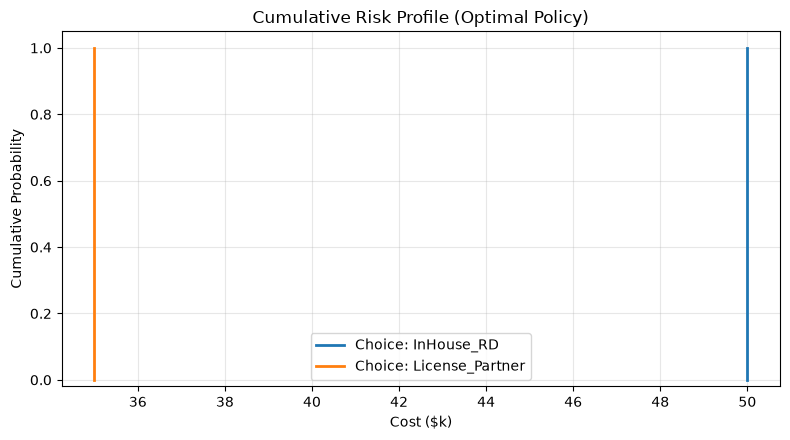

In [4]:
# Exact risk profile table
rp = dt.risk_profile('InHouse_RD', policy='optimal')
display(rp[['outcome', 'probability', 'amount', 'cumulative_probability']])

# Plot cumulative risk profile
fig, ax = plt.subplots(figsize=(8, 4.5))
dt.plot_risk_profile(ax=ax)
ax.set_title('Cumulative Risk Profile (Optimal Policy)')
ax.set_xlabel('Cost ($k)')
ax.set_ylabel('Cumulative Probability')
plt.tight_layout()
plt.show()

## 4. Stochastic Project Scheduling (`ProjectNetwork`)
Complex projects consist of interdependent tasks governed by precedence constraints.
Standard Critical Path Method (CPM) assumes deterministic task durations.
However, realistic tasks follow beta or `PERT(min, mode, max)` distributions.

Let's construct an 11-task project network:
- Task `A` initiates the project.
- Tasks `B1, B2, B3` run concurrently.
- Tasks `C, D1, D2, E` represent engineering pipelines.
- Tasks `F, G` integrate intermediate results.
- Task `H` provides final sign-off.

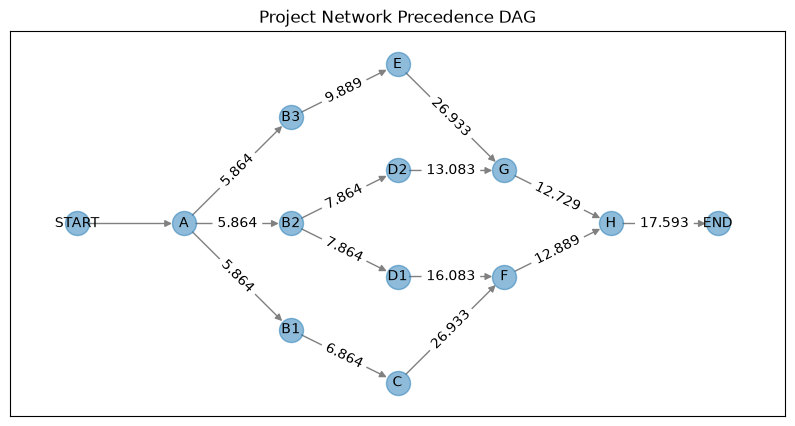

Deterministic 95th-percentile path lengths:


,path,length
0,"(START, A, B1, C, F, H, END)",70.144624
1,"(START, A, B2, D1, F, H, END)",60.293954
2,"(START, A, B2, D2, G, H, END)",57.133989
3,"(START, A, B3, E, G, H, END)",73.009092


In [5]:
net = ProjectNetwork()
net.add_task(ProjectTask('A', PERT(1, 4, 7)))
net.add_task(ProjectTask('B1', PERT(2, 5, 8)), parents='A')
net.add_task(ProjectTask('B2', PERT(3, 6, 9)), parents='A')
net.add_task(ProjectTask('B3', PERT(2, 5, 14)), parents='A')
net.add_task(ProjectTask('C', PERT(6, 21, 30)), parents='B1')
net.add_task(ProjectTask('D1', PERT(5, 14, 17)), parents='B2')
net.add_task(ProjectTask('D2', PERT(2, 11, 14)), parents='B2')
net.add_task(ProjectTask('E', PERT(6, 21, 30)), parents='B3')
net.add_task(ProjectTask('F', PERT(5, 8, 17)), parents=['C', 'D1'])
net.add_task(ProjectTask('G', PERT(3, 9, 15)), parents=['D2', 'E'])
net.add_task(ProjectTask('H', PERT(3, 12, 21)), parents=['F', 'G'], end=True)

# Visualize DAG structure
fig, ax = plt.subplots(figsize=(10, 5))
net.add_percentiles()
net.draw(ax=ax)
plt.title('Project Network Precedence DAG')
plt.show()

print('Deterministic 95th-percentile path lengths:')
display(net.path_lengths())

## 5. Monte Carlo Simulation, Shifting Critical Paths & Task Criticality Index
In deterministic CPM, one single path is designated 'the critical path'.
In reality, because task durations are random variables, **different paths become critical on different runs**!

Using `.critical_path_probabilities()`, we calculate the exact frequency with which each path bottlenecked the project.
Using `.task_criticality_index()`, we rank tasks by $P(\text{Task on critical path})$.

In [6]:
# 1. Critical path probabilities across 2,000 Monte Carlo runs
crit_probs = net.critical_path_probabilities(n_samples=2000, random_state=42)
print('Critical Path Probabilities:')
display(pd.DataFrame({'Probability': crit_probs}))

# 2. Task Criticality Index P(Task is on critical path)
crit_index = net.task_criticality_index(n_samples=2000, random_state=42)
print('\nTask Criticality Index:')
display(pd.DataFrame({'Criticality Index': crit_index}))

Critical Path Probabilities:


,Probability
"(START, A, B3, E, G, H, END)",0.5425
"(START, A, B1, C, F, H, END)",0.4280
"(START, A, B2, D1, F, H, END)",0.0270
"(START, A, B2, D2, G, H, END)",0.0025



Task Criticality Index:


,Criticality Index
A,1.0000
H,1.0000
G,0.5450
B3,0.5425
E,0.5425
F,0.4550
B1,0.4280
C,0.4280
B2,0.0295
D1,0.0270


## 6. Project Completion Time Distribution as a `Ratio` Distribution
The overall completion time is not a single number, but an empirical distribution.
`net.completion_time_distribution()` returns a first-class `Ratio` distribution instance, unlocking all sampling statistics, quantiles, and KDE plotting.

Expected Duration:        53.64 days
Median Duration:          53.63 days
Standard Error:           0.121 days
95% Probability Interval: [43.21, 64.37] days
P(Completion <= 50 days): 24.70%
P(Completion <= 60 days): 87.50%


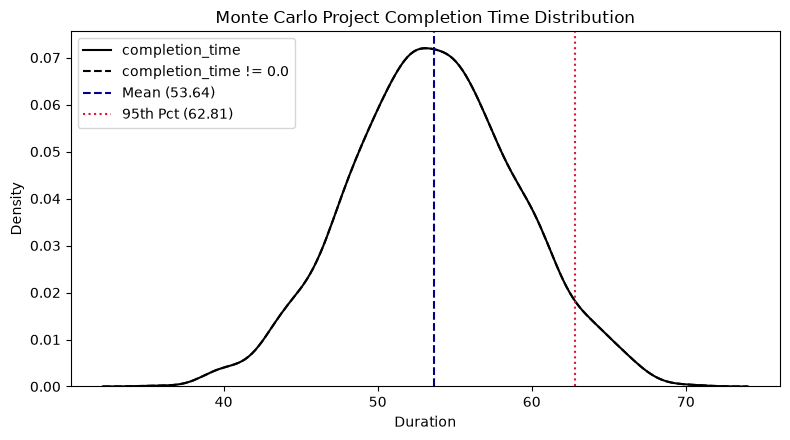

In [7]:
completion_dist = net.completion_time_distribution(n_samples=2000, random_state=42)

print(f'Expected Duration:        {completion_dist.mean():.2f} days')
print(f'Median Duration:          {completion_dist.median():.2f} days')
print(f'Standard Error:           {completion_dist.se():.3f} days')
print(f'95% Probability Interval: [{completion_dist.quantile(0.025):.2f}, {completion_dist.quantile(0.975):.2f}] days')
print(f'P(Completion <= 50 days): {(completion_dist.data <= 50).mean():.2%}')
print(f'P(Completion <= 60 days): {(completion_dist.data <= 60).mean():.2%}')

# Plot KDE distribution with mean and 95th percentile
fig, ax = plt.subplots(figsize=(8, 4.5))
net.plot_completion_time(n_samples=2000, random_state=42, ax=ax)
plt.title('Monte Carlo Project Completion Time Distribution')
plt.tight_layout()
plt.show()